# Washington tire market opportunity: v1.1 rigour checks

Same data snapshot and frozen v1 rules as notebook `wa_tire_opportunity.ipynb`; this notebook only measures how certain the v1 results are. Outputs come from `scripts/run_rigour.py` (code in `src/wa_tire/rigour.py`). Pre-registration and results log: `reports/findings_log.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
from wa_tire import config
from wa_tire.build import load_processed
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 200)
VIEWS = {v: d["short"] for v, d in config.DEALER_VIEWS.items()}
CANDIDATES = {"Kittitas": ["cbp_emp", "sales"], "Asotin": ["sales"]}

## 1. Hypotheses (as pre-registered, before any v1.1 computation)

- **H1:** Kittitas and Asotin are in the top quartile of residuals in ≥ 80% of bootstrap draws that include them.
- **H2:** Their v1 top-candidate flag does not depend on any single other county: it holds in every leave-one-county-out refit.
- **H3:** In each view, the vehicle coefficient's 95% CI excludes 0 and the dealer-activity coefficient's 95% CI includes 0.

Definitions: 2,000 county bootstrap draws (seed 20261015), all years of a county resampled together; top quartile = residual rank ≤ ceil(25% × counties in the draw); H1/H2 checked in every view where the county is assessable (Kittitas: both; Asotin: dealer sales only, since CBP publishes no data for it). CIs use county-clustered SEs and a t critical value with G − 1 degrees of freedom.

## 2. Coefficients with county-clustered 95% CIs (train fit, 2017–2021)

In [2]:
coef = pd.concat({VIEWS[v]: load_processed(f"rigour_coef_ci_{v}") for v in VIEWS}, names=["view"]).droplevel(1).reset_index()
coef

,view,term,coef,se_cluster,ci_low,ci_high,excludes_zero,clusters
0,CBP dealer employment,log_vehicles,0.652,0.163,0.310,0.993,True,20
1,CBP dealer employment,log_dealer,0.148,0.142,-0.150,0.445,False,20
2,dealer sales,log_vehicles,0.398,0.213,-0.039,0.835,False,29
3,dealer sales,log_dealer,0.348,0.165,0.010,0.685,True,29


## 3. Bootstrap rank uncertainty

Each bar spans a county's 90% interval of residual rank across draws (1 = largest residual relative to typical error); the dot is the median rank. The dashed line is the top-quartile cut-off. Candidates are highlighted.

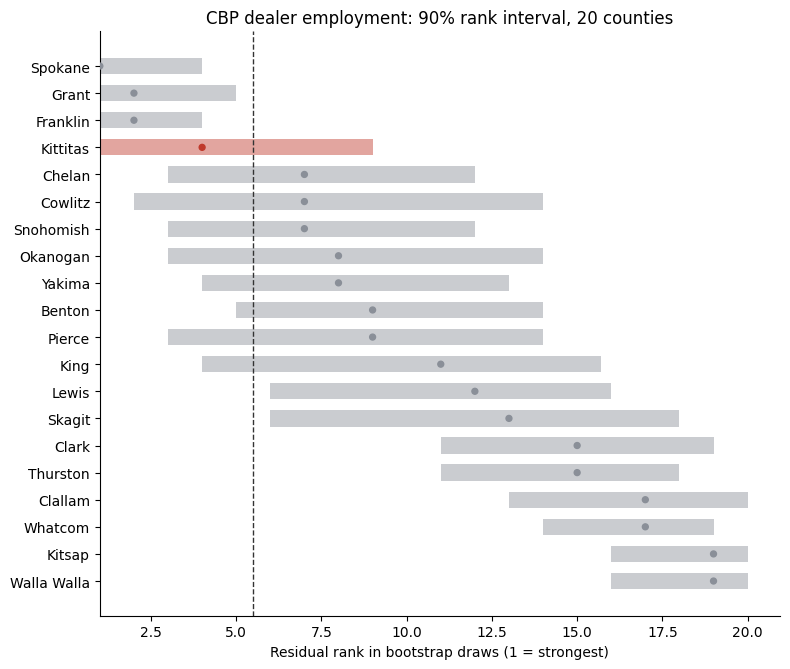

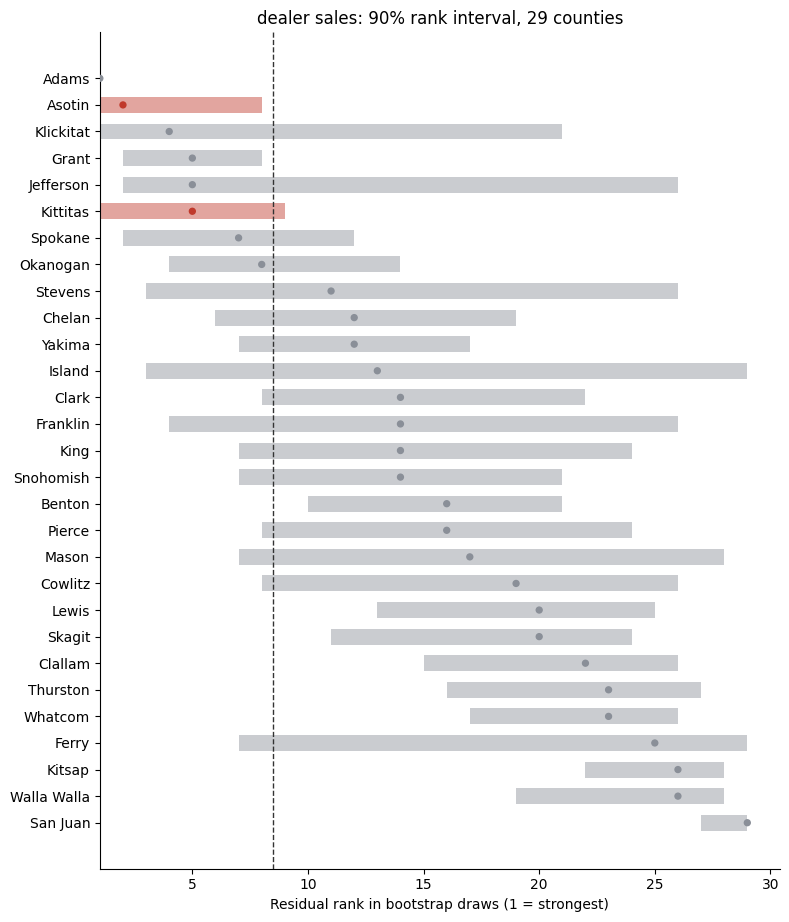

In [3]:
def rank_chart(view):
    b = load_processed(f"rigour_bootstrap_{view}").sort_values("rank_median", ascending=False)
    n = len(load_processed(f"rigour_baseline_{view}"))
    fig, ax = plt.subplots(figsize=(8, 0.28 * len(b) + 1.2))
    colors = ["#c0392b" if c in CANDIDATES else "#8a8f98" for c in b["county"]]
    ax.barh(b["county"], b["rank_high"] - b["rank_low"], left=b["rank_low"], color=colors, alpha=0.45, height=0.6)
    ax.scatter(b["rank_median"], b["county"], color=colors, zorder=3, s=18)
    ax.axvline(np.ceil(config.TOP_SHARE * n) + 0.5, ls="--", color="#333", lw=1)
    ax.set_xlabel("Residual rank in bootstrap draws (1 = strongest)")
    ax.set_title(f"{VIEWS[view]}: 90% rank interval, {n} counties")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

for v in VIEWS:
    rank_chart(v)

In [4]:
cols = ["county", "draws", "rank_median", "rank_low", "rank_high", "pct_top_quartile", "pct_residual_flag", "pct_top_candidate"]
pd.concat({VIEWS[v]: load_processed(f"rigour_bootstrap_{v}")[cols] for v in VIEWS}, names=["view"]).droplevel(1).reset_index().query("pct_top_candidate > 0.1")

,view,county,draws,rank_median,rank_low,rank_high,pct_top_quartile,pct_residual_flag,pct_top_candidate
3,CBP dealer employment,Kittitas,1281,4.000,1.000,9.000,0.719,0.548,0.536
21,dealer sales,Asotin,1277,2.000,1.000,8.000,0.964,0.915,0.914
25,dealer sales,Kittitas,1267,5.000,1.000,9.000,0.924,0.911,0.837
31,dealer sales,Island,1276,13.000,3.000,29.000,0.356,0.359,0.261
38,dealer sales,Mason,1284,17.000,7.000,28.000,0.128,0.185,0.173


## 4. Residual uncertainty

Mean recent log residual (actual vs model, test period) for each county: median and 90% bootstrap interval. The interval reflects uncertainty from which counties the model was fitted on.

In [5]:
cols = ["county", "residual_log_median", "residual_log_low", "residual_log_high"]
res = pd.concat({VIEWS[v]: load_processed(f"rigour_bootstrap_{v}")[cols] for v in VIEWS}, names=["view"]).droplevel(1).reset_index()
res[res["county"].isin(CANDIDATES)]

,view,county,residual_log_median,residual_log_low,residual_log_high
3,CBP dealer employment,Kittitas,0.108,0.009,0.206
21,dealer sales,Asotin,0.670,0.116,1.480
25,dealer sales,Kittitas,0.378,0.185,0.609


Full table for every county: `data/processed/rigour_bootstrap_<view>.csv`.

## 5. Leave-one-county-out

Each view is refitted once per county with that county dropped. The table lists, for each candidate, which dropped counties flip each flag. The second table lists every refit (both views dropped together) in which the tier table differs from v1.

In [6]:
pd.concat({VIEWS[v]: load_processed(f"rigour_loo_changes_{v}") for v in VIEWS}, names=["view"]).droplevel(1).reset_index()

,view,county,refits,residual_flag_v1,residual_flag_changed_by,growth_flag_v1,growth_flag_changed_by,top_candidate_v1,top_candidate_changed_by
0,CBP dealer employment,Kittitas,19,True,"Benton, King, Pierce, Snohomish, Walla Walla",True,none,True,"Benton, King, Pierce, Snohomish, Walla Walla"
1,dealer sales,Kittitas,28,True,none,True,none,True,none
2,dealer sales,Asotin,28,True,none,True,none,True,none


In [7]:
load_processed("rigour_tier_changes")

,dropped,county,tier_v1,tier_now
0,Adams,Island,none,Watch
1,Asotin,Island,none,Watch
2,Klickitat,Island,none,Watch


## 6. Verdicts

In [8]:
boot = {v: load_processed(f"rigour_bootstrap_{v}").set_index("county") for v in VIEWS}
loo = {v: load_processed(f"rigour_loo_changes_{v}").set_index("county") for v in VIEWS}
h1 = {(c, v): boot[v].loc[c, "pct_top_quartile"] for c, vs in CANDIDATES.items() for v in vs}
h2 = {(c, v): loo[v].loc[c, "top_candidate_changed_by"] for c, vs in CANDIDATES.items() for v in vs}
ci = coef.set_index(["view", "term"])["excludes_zero"]
h3 = {VIEWS[v]: bool(ci[(VIEWS[v], "log_vehicles")] and not ci[(VIEWS[v], "log_dealer")]) for v in VIEWS}

def verdict(ok):
    return "**supported**" if ok else "**not supported**"

lines = [f"- **H1** {verdict(all(p >= 0.8 for p in h1.values()))}: "
         + "; ".join(f"{c} ({VIEWS[v]}) {p:.0%}" for (c, v), p in h1.items()),
         f"- **H2** {verdict(all(d == 'none' for d in h2.values()))}: "
         + "; ".join(f"{c} ({VIEWS[v]}) flag changed by: {d}" for (c, v), d in h2.items()),
         f"- **H3** {verdict(all(h3.values()))}: " + "; ".join(f"{k} {'as expected' if ok else 'not as expected'}" for k, ok in h3.items())]
Markdown("\n".join(lines))

- **H1** **not supported**: Kittitas (CBP dealer employment) 72%; Kittitas (dealer sales) 92%; Asotin (dealer sales) 96%
- **H2** **not supported**: Kittitas (CBP dealer employment) flag changed by: Benton, King, Pierce, Snohomish, Walla Walla; Kittitas (dealer sales) flag changed by: none; Asotin (dealer sales) flag changed by: none
- **H3** **not supported**: CBP dealer employment as expected; dealer sales not as expected

**Interpretation.** Tiers do not change: Kittitas and Asotin stay Watch in every leave-one-out refit. What changes is confidence in *why* Kittitas is on the list:

- Under dealer sales, Kittitas and Asotin are stable. They are in the top quartile in over 90% of draws, and no single county removes their flag.
- Under CBP employment (the primary view), Kittitas is fragile. Its residual is 1.06× typical error, just over the threshold. It is in the top quartile in about 72% of draws and is a top candidate in about 54%. Dropping any one of Benton, King, Pierce, Snohomish or Walla Walla removes its flag. If that happens, Kittitas becomes "flagged under dealer sales only" and is still Watch, because the concentration cap already holds it there.
- Coefficients are less clear-cut than the v1 p-values suggested. In the CBP view, vehicles matter and dealer employment does not, as expected. In the dealer-sales view (29 clusters, t critical value), the vehicle CI includes 0 and the dealer-sales CI just excludes 0. With 20–29 clusters, neither view separates vehicles from dealer activity cleanly.
- Island becomes Watch (dealer sales only) when Adams, Asotin or Klickitat is dropped. So Island sits just below the cut-off, but it is not a v1 candidate.